### Imports

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(".")); os.chdir("..")
import torch, numpy as np
import matplotlib.pyplot as plt
from utils import set_seed, _psnr, load_model, compose_player_prompts
set_seed(42)
IMG_H, IMG_W = 96, 96
device = "cuda"

from data_rollout import get_registries, _skip_intro, _camera_state
from buffer import OrthoTransitionBuffer
from data_rollout import collect_all_envs_rollouts
from models import encode_views_to_latents, decode_latents_to_views
from flow import train_ortho_flow_step, train_ortho_trajectory_step, predict_next_view_latents

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
Users of this version of Gym should be able to simply replace 'import gym' with 'import gymnasium as gym' in the vast majority of cases.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


In [2]:
train_reg, heldout_reg = get_registries()
env = dict(train_reg)["MultiCar Racing"]()
obs, _ = env.reset(seed=0); obs = _skip_intro(env, "MultiCar Racing", obs)
top, rear, side, fpv = env.render(camera_pose="Center")

/home/dexterneo/anaconda3/envs/GAME/lib/python3.11/site-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


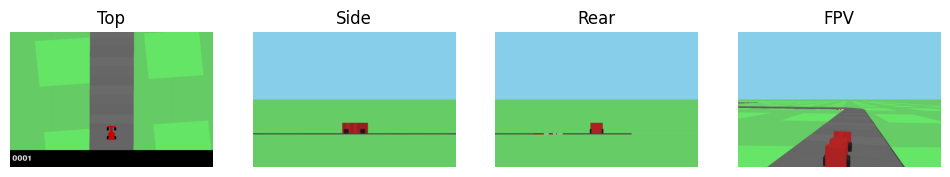

In [3]:
fig, ax = plt.subplots(1, 4, figsize=(12, 3))
for a, im, t in zip(ax, [top, side, rear, fpv], ["Top", "Side", "Rear", "FPV"]): 
    a.imshow(im)
    a.set_title(t)
    a.axis("off")

### Collect rollouts into buffer

In [4]:
# Sample trajectories from the buffer
ENV = "MultiCar Racing"
buffer = OrthoTransitionBuffer(capacity=256, img_h=IMG_H, img_w=IMG_W, max_action_len=8)
active_envs, agents = collect_all_envs_rollouts([(ENV, dict(train_reg)[ENV])], buffer,
                                                rollout_steps=256, num_envs=1, seed=42, device=device)


[1/1] Initializing environment: MultiCar Racing


/home/dexterneo/anaconda3/envs/GAME/lib/python3.11/site-packages/stable_baselines3/common/save_util.py:167: UserWarning: Could not deserialize object clip_range. Consider using `custom_objects` argument to replace this object.
Exception: code() argument 13 must be str, not int
  warnings.warn(
/home/dexterneo/anaconda3/envs/GAME/lib/python3.11/site-packages/stable_baselines3/common/save_util.py:167: UserWarning: Could not deserialize object lr_schedule. Consider using `custom_objects` argument to replace this object.
Exception: code() argument 13 must be str, not int
  warnings.warn(
Rollouts [MultiCar Racing]: 100%|█████████████████████████████████████████████████████| 256/256 [00:19<00:00, 13.35it/s]


[INFO] Buffer populated with 256 transitions across 1 environments: MultiCar Racing


In [5]:
# Sample trajectories from the buffer
views_t, views_next_seq, actions_seq, env_names_seq, cams_seq = buffer.sample_trajectory_batch(batch_size=2, seq_len=4)

### Prompt building for Diffusion Model

In [6]:
prompts = compose_player_prompts(actions_seq[0], env_name=env_names_seq[0], camera_pose=cams_seq[0])
print(prompts[0])

MultiCar circuit racing: camera Right, x: +136, y: -27, z: +16, yaw: +8 deg, pitch: +45 deg, steer +0.39, throttle 0.66, brake 0.00, racing at high speed on a track.


In [7]:
model, vae, text_encoder, tokenizer = load_model(model_id="Wan-AI/Wan2.1-T2V-1.3B-Diffusers", lora_rank=16)
lat = encode_views_to_latents(vae, views_t.to(device), out_dtype=model.dtype)
rec = decode_latents_to_views(vae, lat)


[INFO] Loading Wan2.1 components from: Wan-AI/Wan2.1-T2V-1.3B-Diffusers


Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/242 [00:00<?, ?it/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

trainable params: 21,872,640 || all params: 1,440,869,440 || trainable%: 1.5180


In [8]:
print("VAE ceiling PSNR:", _psnr(rec.to(device), (views_t + 1) / 2))

VAE ceiling PSNR: 32.898301523601205


### Diffusion training step
1. Walk through the function body: \
  a. Sample τ from a shifted logit-normal distribution. \
  b. Add a little noise to the context frames (against drift). \
  c. Build the input cat([context t (frames 0–3), noisy t+1 (frames 4–7)]). \
  d. Target velocity v = ε − x₀, with a separate loss per view. \ 
  e. One-step estimate x̂₀ = x_τ − τ·v̂. \
2. Show: decode x0_hat at a few τ values

In [9]:
with torch.no_grad():
    tok = tokenizer(prompts, padding="max_length", max_length=128, truncation=True, return_tensors="pt").to(device)
    emb = text_encoder(**tok).last_hidden_state.to(model.dtype)
    lat_next = encode_views_to_latents(vae, views_next_seq[0].to(device), out_dtype=model.dtype)
    loss, per_view, x0_hat = train_ortho_flow_step(model, lat, lat_next, emb)

In [10]:
optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=3e-4)
latents_next_seq, prompt_embeds_seq = [], []

with torch.no_grad():
    for s in range(len(views_next_seq)):
        latents_next_seq.append(encode_views_to_latents(vae, views_next_seq[s].to(device), out_dtype=model.dtype))
        p = compose_player_prompts(actions_seq[s], env_name=env_names_seq[s], camera_pose=cams_seq[s])
        tk = tokenizer(p, padding="max_length", max_length=128, truncation=True, return_tensors="pt").to(device)
        prompt_embeds_seq.append(text_encoder(**tk).last_hidden_state.to(model.dtype))
optimizer.zero_grad(set_to_none=True)
loss, per_view = train_ortho_trajectory_step(model, lat, latents_next_seq, prompt_embeds_seq,
                                             teacher_forcing_prob=0.5, sf_steps=8)
optimizer.step()
print(loss, per_view)

1.2484498918056488 [0.5309231951832771, 0.21505321189761162, 0.20006529055535793, 0.30240820348262787]


In [12]:
nxt = predict_next_view_latents(model, lat, emb, steps=20)       # reverse Euler from noise
from validation import autoregressive_rollout
env = dict(heldout_reg)["Parkour Runner"]()
(g_top, g_rear, g_side, g_fpv, gt_top, gt_rear, gt_side, gt_fpv,
 g_fpv_vis, gt_fpv_vis, _) = autoregressive_rollout(model, vae, text_encoder, tokenizer, "Parkour Runner", env,
                                                    agent=agents["MultiCar Racing"], rollout_steps=16, steps=20,
                                                    img_hw=(IMG_H, IMG_W))
print("FPV PSNR:", _psnr(g_fpv, gt_fpv))

Starting 16-step Autoregressive Rollout for [Parkour Runner] (camera Right)...


ValueError: axes don't match array

### GymBox inputs → HiFi outputs
Same physics, same camera, Cross View Renderer: GymBox (input) -> Godot (output)

In [16]:
sys.path.insert(0, os.path.abspath("hifi"))
from wrappers import make_hifi_env
henv = make_hifi_env(ENV, pair=True)          # starts Godot off-screen (xvfb); ~0.5 s per frame on WSL
obs, _ = henv.reset(seed=0); obs = _skip_intro(henv, ENV, obs)
hi = henv.render(camera_pose="Center")        # Godot:  (top, rear, side, fpv)
lo = henv.last_lowfi                          # GymBox: same state and camera

[hifi] waiting for Godot on port 43311 ...


In [17]:
import cv2
def to_views(frames):   # render order (top, rear, side, fpv) -> (4, 3, H, W) in [-1, 1], buffer order
    top, rear, side, fpv = frames
    v = [cv2.resize(x, (IMG_W, IMG_H), interpolation=cv2.INTER_AREA) for x in (top, side, rear, fpv)]
    return torch.from_numpy(np.stack(v)).permute(0, 3, 1, 2).float() / 127.5 - 1.0

lo_seq, hi_seq, act_seq, cam_seq = [to_views(lo)], [to_views(hi)], [], []
for t in range(16):
    action, _ = agents[ENV].predict(obs, deterministic=True)
    obs, _, term, trunc, _ = henv.step(action)
    hi = henv.render(camera_pose="Right")
    lo_seq.append(to_views(henv.last_lowfi)); hi_seq.append(to_views(hi))
    act_seq.append(np.atleast_1d(np.asarray(action, dtype=np.float32)))
    cam_seq.append(_camera_state(henv, "Right"))
    if term or trunc: break
lo_views, hi_views = torch.stack(lo_seq), torch.stack(hi_seq)   # (T+1, 4, 3, H, W)
henv.close()

In [18]:
with torch.no_grad():
    lat_lo = encode_views_to_latents(vae, lo_views[:-1].to(device), out_dtype=model.dtype)   # inputs at t
    lat_hi = encode_views_to_latents(vae, hi_views[1:].to(device),  out_dtype=model.dtype)   # targets at t+1
    p = compose_player_prompts(act_seq, env_name=ENV, camera_pose=cam_seq)
    tk = tokenizer(p, padding="max_length", max_length=128, truncation=True, return_tensors="pt").to(device)
    emb_pair = text_encoder(**tk).last_hidden_state.to(model.dtype)
    loss, per_view, x0_hat = train_ortho_flow_step(model, lat_lo, lat_hi, emb_pair)
print(f"GymBox->HiFi loss {loss.item():.3f}  per view {per_view}")
print("GymBox vs HiFi PSNR (domain gap):", _psnr((lo_views + 1) / 2, (hi_views + 1) / 2))
henv.close()

GymBox->HiFi loss 1.074  per view [0.33846816420555115, 0.23519212007522583, 0.2230016440153122, 0.2775230407714844]
GymBox vs HiFi PSNR (domain gap): 10.790851809016996
